# Multi-class Dog Breed Classification (PyTorch)

This notebook builds an end-to-end multi-class image classifier using **PyTorch** and **torchvision**

## 1. Problem

Identifying the breed of a dog given an image of a dog.

## 2. Data

The data we're using is from Kaggle's dog breed identification competition.

https://www.kaggle.com/c/dog-breed-identification/data

## 3. Features

Some information about the data:
* We're dealing with images (unstructured data) so it's probably best we use deep learning/transfer learning.
* There are 120 breeds of dogs (this means there are 120 different classes).
* There are around 10,000+ images in the training set (these images have labels).
* There are around 10,000+ images in the test set (these images have no labels, because we'll want to predict them).


## Setup

In [1]:
# Import necessary tools
import os
import datetime

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image

import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader
# from torch.utils.tensorboard import SummaryWriter
import torchvision
from torchvision import transforms
from torchvision.models import mobilenet_v2, MobileNet_V2_Weights
from torchvision.models import efficientnet_b0, EfficientNet_B0_Weights


from sklearn.model_selection import train_test_split

print("PyTorch version:", torch.__version__)
print("Torchvision version:", torchvision.__version__)

# Check for GPU availability
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Using device:", device, "(Y)" if device.type == "cuda" else "(no GPU found :( )")


PyTorch version: 2.14.0+cu126
Torchvision version: 0.29.0+cu126
Using device: cuda (Y)


## 1. Get our data ready (turning into Tensors)

In [2]:
# Checkout the labels of our data
labels_csv = pd.read_csv("labels.csv")
print(labels_csv.describe())
print(labels_csv.head())


                                      id               breed
count                              10222               10222
unique                             10222                 120
top     000bec180eb18c7604dcecc8fe0dba07  scottish_deerhound
freq                                   1                 126
                                 id             breed
0  000bec180eb18c7604dcecc8fe0dba07       boston_bull
1  001513dfcb2ffafc82cccf4d8bbaba97             dingo
2  001cdf01b096e06d78e9e5112d419397          pekinese
3  00214f311d5d2247d5dfe4fe24b2303d          bluetick
4  0021f9ceb3235effd7fcde7f7538ed62  golden_retriever


<Axes: xlabel='breed'>

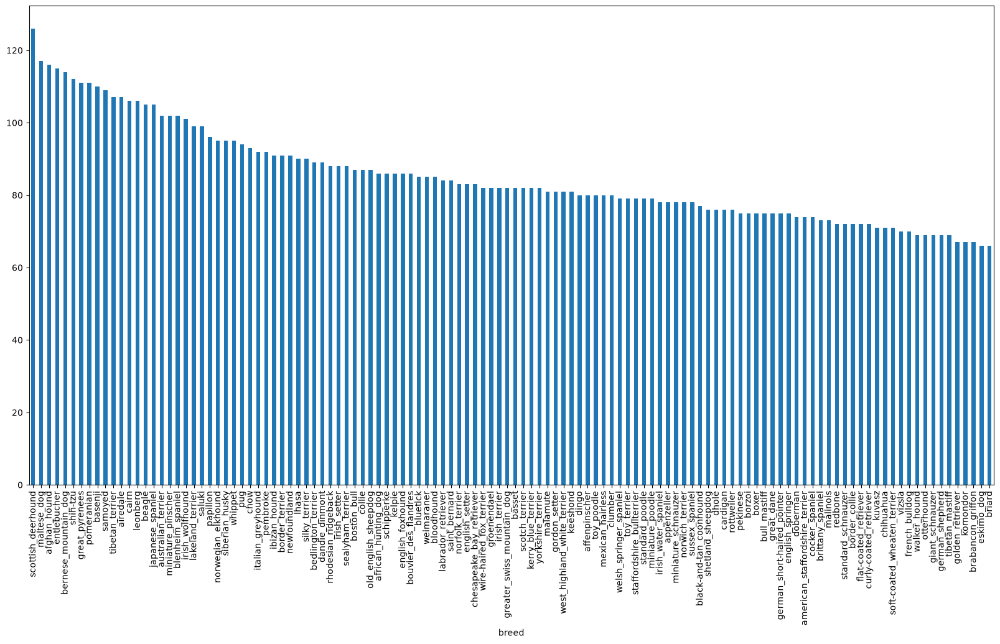

In [3]:
# How many images are there of each breed?
labels_csv["breed"].value_counts().plot.bar(figsize=(20, 10))


In [4]:
# median number of images per class?
labels_csv["breed"].value_counts().median()


np.float64(82.0)

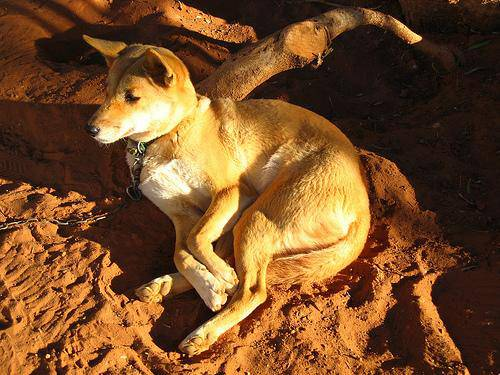

In [5]:
# Let's view an image
Image.open("train/001513dfcb2ffafc82cccf4d8bbaba97.jpg")


In [6]:
# Create pathnames from image ID's
filenames = ["train/" + fname + ".jpg" for fname in labels_csv["id"]]

filenames[:10]


['train/000bec180eb18c7604dcecc8fe0dba07.jpg',
 'train/001513dfcb2ffafc82cccf4d8bbaba97.jpg',
 'train/001cdf01b096e06d78e9e5112d419397.jpg',
 'train/00214f311d5d2247d5dfe4fe24b2303d.jpg',
 'train/0021f9ceb3235effd7fcde7f7538ed62.jpg',
 'train/002211c81b498ef88e1b40b9abf84e1d.jpg',
 'train/00290d3e1fdd27226ba27a8ce248ce85.jpg',
 'train/002a283a315af96eaea0e28e7163b21b.jpg',
 'train/003df8b8a8b05244b1d920bb6cf451f9.jpg',
 'train/0042188c895a2f14ef64a918ed9c7b64.jpg']

In [7]:
# Check whether number of filenames matches number of actual image files
if len(os.listdir("train/")) == len(filenames):
  print("match")
else:
  print("no match")


match


In [8]:
# Check breed for a given index
labels_csv["breed"][900]


'lhasa'

### Getting our labels ready (turning them into numbers)

In [9]:
labels = labels_csv["breed"].to_numpy()
labels


array(['boston_bull', 'dingo', 'pekinese', ..., 'airedale',
       'miniature_pinscher', 'chesapeake_bay_retriever'],
      shape=(10222,), dtype=object)

In [10]:
len(labels)


10222

In [11]:
# See if number of labels matches the number of filenames
if len(labels) == len(filenames):
  print("match")
else:
  print("no match")


match


In [12]:
# Find the unique label values (sorted alphabetically, this becomes our class index order)
unique_breeds = np.unique(labels)
len(unique_breeds)
unique_breeds

array(['affenpinscher', 'afghan_hound', 'african_hunting_dog', 'airedale',
       'american_staffordshire_terrier', 'appenzeller',
       'australian_terrier', 'basenji', 'basset', 'beagle',
       'bedlington_terrier', 'bernese_mountain_dog',
       'black-and-tan_coonhound', 'blenheim_spaniel', 'bloodhound',
       'bluetick', 'border_collie', 'border_terrier', 'borzoi',
       'boston_bull', 'bouvier_des_flandres', 'boxer',
       'brabancon_griffon', 'briard', 'brittany_spaniel', 'bull_mastiff',
       'cairn', 'cardigan', 'chesapeake_bay_retriever', 'chihuahua',
       'chow', 'clumber', 'cocker_spaniel', 'collie',
       'curly-coated_retriever', 'dandie_dinmont', 'dhole', 'dingo',
       'doberman', 'english_foxhound', 'english_setter',
       'english_springer', 'entlebucher', 'eskimo_dog',
       'flat-coated_retriever', 'french_bulldog', 'german_shepherd',
       'german_short-haired_pointer', 'giant_schnauzer',
       'golden_retriever', 'gordon_setter', 'great_dane',
      

In [14]:
len(unique_breeds)

120

In [15]:
# Map each breed string to an integer class index.

breed_to_idx = {breed: idx for idx, breed in enumerate(unique_breeds)}
idx_to_breed = {idx: breed for breed, idx in breed_to_idx.items()}

labels_int = np.array([breed_to_idx[label] for label in labels])
print(labels[0], "=", labels_int[0])
labels_int[:10]

boston_bull = 19


array([19, 37, 85, 15, 49, 10, 10, 18,  7, 97])

In [16]:
len(labels_int)

10222

### Creating our own validation set Since the dataset doesn't come with a validation set, we're going to create our own.

In [17]:
# Setup X & y variables
X = filenames
y = labels_int


In [18]:
len(filenames)


10222

In [19]:
# Set number of images to use for experimenting
NUM_IMAGES = 1000


In [21]:
# Let's split our data into train and validation sets
# Split them into training and validation of total size NUM_IMAGES
X_train, X_val, y_train, y_val = train_test_split(X[:NUM_IMAGES],
                                                    y[:NUM_IMAGES],
                                                    test_size=0.2,
                                                    random_state=42)

len(X_train), len(y_train), len(X_val), len(y_val)


(800, 800, 200, 200)

In [22]:
# Let's have a look at the training data
X_train[:5], y_train[:2]


(['train/00bee065dcec471f26394855c5c2f3de.jpg',
  'train/0d2f9e12a2611d911d91a339074c8154.jpg',
  'train/1108e48ce3e2d7d7fb527ae6e40ab486.jpg',
  'train/0dc3196b4213a2733d7f4bdcd41699d3.jpg',
  'train/146fbfac6b5b1f0de83a5d0c1b473377.jpg'],
 array([26, 20]))

### Preprocessing images (turning images into Tensors)

In [23]:
# Take a look at an image
image = Image.open(filenames[42])
image = np.array(image)
image.shape

(257, 350, 3)

In [24]:
image.max(), image.min()


(np.uint8(255), np.uint8(0))

In [25]:
image[:2]


array([[[ 89, 137,  89],
        [ 76, 124,  76],
        [ 63, 111,  61],
        ...,
        [ 77, 133,  86],
        [ 76, 134,  86],
        [ 76, 134,  86]],

       [[ 72, 119,  75],
        [ 67, 114,  68],
        [ 63, 110,  64],
        ...,
        [ 75, 131,  84],
        [ 74, 132,  84],
        [ 74, 132,  84]]], shape=(2, 350, 3), dtype=uint8)

In [26]:
# Turn the image into a Tensor
torch.tensor(image)[:2]


tensor([[[ 89, 137,  89],
         [ 76, 124,  76],
         [ 63, 111,  61],
         ...,
         [ 77, 133,  86],
         [ 76, 134,  86],
         [ 76, 134,  86]],

        [[ 72, 119,  75],
         [ 67, 114,  68],
         [ 63, 110,  64],
         ...,
         [ 75, 131,  84],
         [ 74, 132,  84],
         [ 74, 132,  84]]], dtype=torch.uint8)

In [27]:
# Define image size
IMG_SIZE = 224

# ImageNet mean/std, required for the pretrained MobileNetV2 backbone
IMAGENET_MEAN = [0.485, 0.456, 0.406]
IMAGENET_STD = [0.229, 0.224, 0.225]


#transforming the training imgs
train_transform = transforms.Compose([
    transforms.Resize((IMG_SIZE,IMG_SIZE)),
    transforms.RandomResizedCrop(IMG_SIZE, scale=(0.7, 1.0)),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomRotation(15),
    transforms.ColorJitter(
        brightness=0.2,
        contrast=0.2,
        saturation=0.2,
        hue=0.05
    ),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=IMAGENET_MEAN,
        std=IMAGENET_STD
    ),
])

model_transform = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.ToTensor(), 
    transforms.Normalize(mean=IMAGENET_MEAN, std=IMAGENET_STD),
])

# This transform is only for *displaying* images (no normalization, so colours look right)
display_transform = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.ToTensor(),
])


def process_image(image_path, transform=model_transform):
  """
  Takes an image file path and turns the image into a normalized Tensor,
  ready to be fed into the model.
  """
  image = Image.open(image_path).convert("RGB")  # force 3 colour channels (RGB)
  image = transform(image)
  return image


def unnormalize(tensor_image):
  """
  Takes a normalized (C, H, W) image Tensor and turns it back into a
  displayable (H, W, C) NumPy array in the range [0, 1].
  """
  mean = torch.tensor(IMAGENET_MEAN).view(3, 1, 1)
  std = torch.tensor(IMAGENET_STD).view(3, 1, 1)
  image = tensor_image.cpu() * std + mean
  image = image.clamp(0, 1)
  return image.permute(1, 2, 0).numpy()


In [28]:
# Demo of the above
process_image(X[42]).shape, y[42]


(torch.Size([3, 224, 224]), np.int64(36))

### Turning our data into batches

In [29]:
class DogDataset(Dataset):
  
  #A PyTorch Dataset which loads dog images 
  
  def __init__(self, filepaths, labels=None, transform=model_transform):
    self.filepaths = filepaths
    self.labels = labels
    self.transform = transform

  def __len__(self):
    return len(self.filepaths)

  def __getitem__(self, idx):
    image = process_image(self.filepaths[idx], transform=self.transform)
    if self.labels is None:
      return image
    label = torch.tensor(self.labels[idx], dtype=torch.long)
    return image, label


In [30]:
# Define the batch size, 32 
BATCH_SIZE = 32


def create_data_batches(X, y=None, batch_size=BATCH_SIZE, valid_data=False, test_data=False,
                         transform=model_transform, num_workers=0):
  """
  Creates batches (a DataLoader) out of image (X) and label (y) pairs.
  Shuffles the data if it's training data but doesn't shuffle if it's
  validation data. Also accepts test data as input (no labels).
  """
  # If the data is a test dataset, we probably don't have labels
  if test_data:
    print("Creating test data batches...")
    dataset = DogDataset(X, labels=None, transform=transform)
    return DataLoader(dataset, batch_size=batch_size, shuffle=False, num_workers=num_workers)

  # If the data is a valid dataset, we don't need to shuffle it
  elif valid_data:
    print("Creating validation data batches...")
    dataset = DogDataset(X, labels=y, transform=transform)
    return DataLoader(dataset, batch_size=batch_size, shuffle=False, num_workers=num_workers)

  else:
    print("Creating training data batches...")
    dataset = DogDataset(X, labels=y, transform=transform)
    return DataLoader(dataset, batch_size=batch_size, shuffle=True, num_workers=num_workers)


In [31]:
# Create training and validation data batches
train_data = create_data_batches(X_train, y_train, transform = train_transform)
val_data = create_data_batches(X_val, y_val,transform = model_transform, valid_data=True)


Creating training data batches...
Creating validation data batches...


In [32]:
# Check out the shape of a batch from our data loaders
train_images, train_labels = next(iter(train_data))
val_images, val_labels = next(iter(val_data))
train_images.shape, train_labels.shape, val_images.shape, val_labels.shape


(torch.Size([32, 3, 224, 224]),
 torch.Size([32]),
 torch.Size([32, 3, 224, 224]),
 torch.Size([32]))

### Visualizing data batches

In [33]:
# Create a function for viewing images in a data batch
def show_25_images(images, labels):
  """
  Displays a plot of 25 images and their labels from a data batch.
  `images` is expected to be a batch Tensor (N, C, H, W) of *normalized*
  images (straight out of a DataLoader), and `labels` a batch of integer
  class indices.
  """
  plt.figure(figsize=(10, 10))
  for i in range(min(25, len(images))):
    ax = plt.subplot(5, 5, i + 1)
    plt.imshow(unnormalize(images[i]))
    plt.title(unique_breeds[labels[i]])
    plt.axis("off")


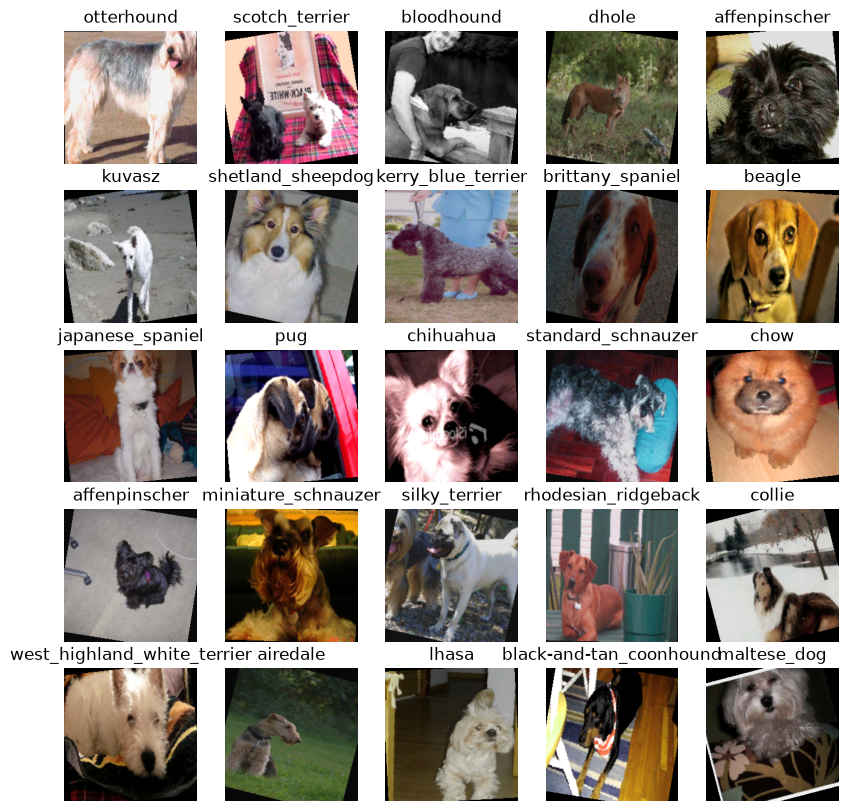

In [34]:
# Now let's visualize the data in a training batch
train_images, train_labels = next(iter(train_data))
show_25_images(train_images, train_labels)


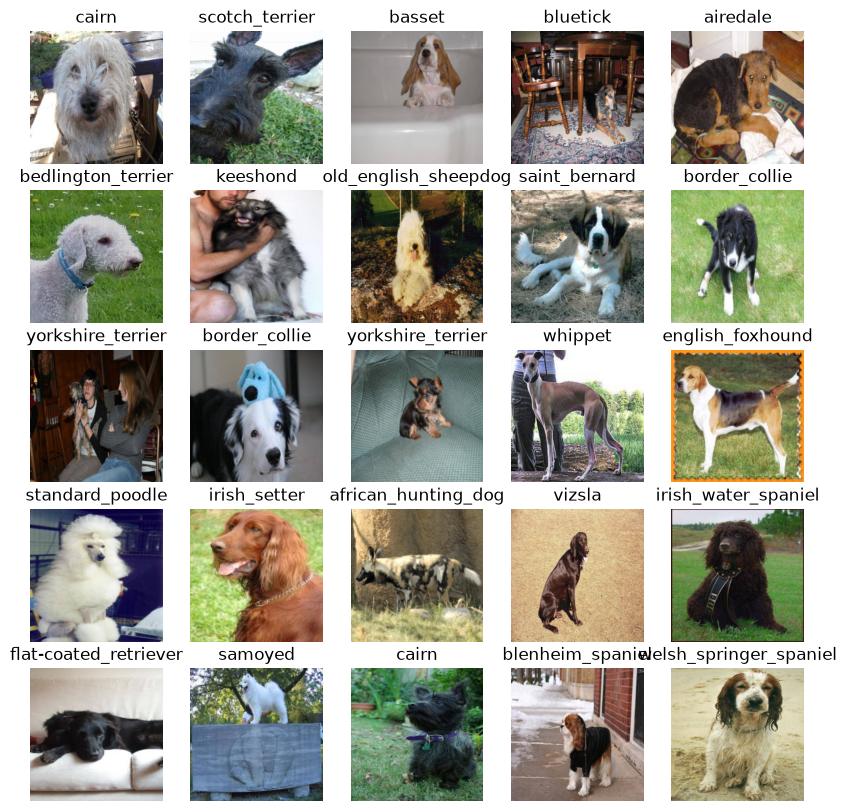

In [35]:
# Now let's visualize our validation set
val_images, val_labels = next(iter(val_data))
show_25_images(val_images, val_labels)


## 2. Building a model. We'll use transfer learning: a MobileNetV2 backbone pretrained on ImageNet

In [36]:
# Setup input shape to the model
INPUT_SHAPE = (3, IMG_SIZE, IMG_SIZE)  # colour channels, height, width

# Setup output shape of our model
OUTPUT_SHAPE = len(unique_breeds)


In [37]:
INPUT_SHAPE


(3, 224, 224)

In [61]:
def create_model(output_shape=OUTPUT_SHAPE, freeze_base=True):
  """
  Builds a MobileNetV2 model pretrained on ImageNet, with its classifier
  head replaced so it outputs `output_shape` classes. 
  """
  print("Building model with a pretrained MobileNetV2 backbone")

  weights = MobileNet_V2_Weights.IMAGENET1K_V1
  model = mobilenet_v2(weights=weights)


  if freeze_base:
    # Freeze the pretrained feature-extractor layers so only the new head gets trained.
    for param in model.features.parameters():
      param.requires_grad = False

  # Replace the final classifier layer (Layer 2 / output layer)
  in_features = model.classifier[-1].in_features
  model.classifier = nn.Sequential(
    nn.Dropout(p=0.4),
    nn.Linear(in_features, output_shape)
)

  model = model.to(device)
  return model


In [62]:
model = create_model()
print(model.classifier)


Building model with a pretrained MobileNetV2 backbone
Sequential(
  (0): Dropout(p=0.4, inplace=False)
  (1): Linear(in_features=1280, out_features=120, bias=True)
)


In [63]:
# Total vs trainable parameter counts (rough equivalent of model.summary())
total_params = sum(p.numel() for p in model.parameters())
trainable_params = sum(p.numel() for p in model.parameters() if p.requires_grad)
print(f"Total params: {total_params:,}")
print(f"Trainable params: {trainable_params:,}")


Total params: 2,377,592
Trainable params: 153,720


In [64]:
# pip install tensorboard

### Creating callbacks.

In [65]:
from torch.utils.tensorboard import SummaryWriter
def create_tensorboard_writer():
  """
  Creates a torch.utils.tensorboard.SummaryWriter that logs to a timestamped
  directory.
  """
  logdir = os.path.join("logs/",
                        datetime.datetime.now().strftime("%Y%m%d-%H%M%S"))
  return SummaryWriter(log_dir=logdir)


In [66]:
class EarlyStopping:
  """
  A minimal re-implementation of tf.keras.callbacks.EarlyStopping.
  Call `.step(metric)` after each epoch; check `.should_stop` to decide
  whether to break out of the training loop.
  """
  def __init__(self, patience=3, mode="max"):
    self.patience = patience
    self.mode = mode
    self.best_score = None
    self.counter = 0
    self.should_stop = False

  def step(self, metric):
    if self.best_score is None:
      self.best_score = metric
      return
    improved = (metric > self.best_score) if self.mode == "max" else (metric < self.best_score)
    if improved:
      self.best_score = metric
      self.counter = 0
    else:
      self.counter += 1
      if self.counter >= self.patience:
        self.should_stop = True


# Early stopping, watching validation accuracy, patience of 3 epochs
# (equivalent to monitor="val_accuracy", patience=3 in the original notebook)
early_stopping = EarlyStopping(patience=3, mode="max")


In [67]:
NUM_EPOCHS = 100


In [68]:
# Check to make sure we're still running on a GPU
print("Using device:", device, "(Y)" if device.type == "cuda" else "(no GPU found :( )")


Using device: cuda (Y)


### Training a model (on a subset of data)

In [69]:
def train_one_epoch(model, dataloader, criterion, optimizer, device):
  """Runs one epoch of training and returns (avg_loss, accuracy)."""
  model.train()
  running_loss, running_correct, running_total = 0.0, 0, 0

  for images, labels in dataloader:
    images, labels = images.to(device), labels.to(device)

    optimizer.zero_grad()
    outputs = model(images)
    loss = criterion(outputs, labels)
    loss.backward()
    optimizer.step()

    running_loss += loss.item() * images.size(0)
    running_correct += (outputs.argmax(dim=1) == labels).sum().item()
    running_total += images.size(0)

  return running_loss / running_total, running_correct / running_total


@torch.no_grad()
def evaluate(model, dataloader, criterion, device):
  """Runs evaluation (no gradient updates) and returns (avg_loss, accuracy)."""
  model.eval()
  running_loss, running_correct, running_total = 0.0, 0, 0

  for images, labels in dataloader:
    images, labels = images.to(device), labels.to(device)
    outputs = model(images)
    loss = criterion(outputs, labels)

    running_loss += loss.item() * images.size(0)
    running_correct += (outputs.argmax(dim=1) == labels).sum().item()
    running_total += images.size(0)

  return running_loss / running_total, running_correct / running_total


In [70]:
# # LEARNING_RATE = 1e-4
def train_model(train_dataloader, val_dataloader=None, epochs=NUM_EPOCHS, patience=3):
  """
  Builds and trains a model, returning the trained version. 
  """
  model = create_model()
  criterion = nn.CrossEntropyLoss()
  optimizer = optim.AdamW([
      {
          "params":model.features.parameters(),
          "lr":1e-5
      },
      {
          "params":model.classifier.parameters(),
          "lr":1e-4
      }
  ],
    # filter(lambda p: p.requires_grad, model.parameters()),
    weight_decay=1e-4
)

  writer = create_tensorboard_writer()
  stopper = EarlyStopping(patience=patience, mode="max")

  for epoch in range(epochs):
    train_loss, train_acc = train_one_epoch(model, train_dataloader, criterion, optimizer, device)
    writer.add_scalar("Loss/train", train_loss, epoch)
    writer.add_scalar("Accuracy/train", train_acc, epoch)

    log_line = f"Epoch {epoch + 1}/{epochs} - train_loss: {train_loss:.4f} - train_acc: {train_acc:.4f}"

    if val_dataloader is not None:
      val_loss, val_acc = evaluate(model, val_dataloader, criterion, device)
      writer.add_scalar("Loss/val", val_loss, epoch)
      writer.add_scalar("Accuracy/val", val_acc, epoch)
      log_line += f" - val_loss: {val_loss:.4f} - val_acc: {val_acc:.4f}"
      stopper.step(val_acc)
    else:
      # No validation set (e.g. training on the full dataset): watch train accuracy instead
      stopper.step(train_acc)

    print(log_line)

    if stopper.should_stop:
      print(f"Early stopping triggered after epoch {epoch + 1}.")
      break

  writer.close()
  return model

In [71]:
# Fit the model to the data
model = train_model(train_data, val_data)


Building model with a pretrained MobileNetV2 backbone
Epoch 1/100 - train_loss: 4.8925 - train_acc: 0.0088 - val_loss: 4.8763 - val_acc: 0.0050
Epoch 2/100 - train_loss: 4.6772 - train_acc: 0.0213 - val_loss: 4.7960 - val_acc: 0.0150
Epoch 3/100 - train_loss: 4.5265 - train_acc: 0.0400 - val_loss: 4.6979 - val_acc: 0.0400
Epoch 4/100 - train_loss: 4.4422 - train_acc: 0.0537 - val_loss: 4.6064 - val_acc: 0.0400
Epoch 5/100 - train_loss: 4.2954 - train_acc: 0.0850 - val_loss: 4.5067 - val_acc: 0.0550
Epoch 6/100 - train_loss: 4.1497 - train_acc: 0.1237 - val_loss: 4.4186 - val_acc: 0.1000
Epoch 7/100 - train_loss: 4.0238 - train_acc: 0.1550 - val_loss: 4.3414 - val_acc: 0.1100
Epoch 8/100 - train_loss: 3.9389 - train_acc: 0.2025 - val_loss: 4.2517 - val_acc: 0.1200
Epoch 9/100 - train_loss: 3.8283 - train_acc: 0.2462 - val_loss: 4.1527 - val_acc: 0.1700
Epoch 10/100 - train_loss: 3.7348 - train_acc: 0.2712 - val_loss: 4.0795 - val_acc: 0.2050
Epoch 11/100 - train_loss: 3.6248 - train_acc

## 3. Making and evaluating predictions using a trained model

In [210]:
@torch.no_grad()
def predict_probabilities(model, dataloader):
  """
  Runs a model over a DataLoader and returns a NumPy array of softmax
  prediction probabilities, shape (num_samples, num_classes). 
  """
  model.eval()
  all_probs = []
  for batch in dataloader:
    images = batch[0] if isinstance(batch, (list, tuple)) else batch
    images = images.to(device)
    logits = model(images)
    probs = torch.softmax(logits, dim=1)
    all_probs.append(probs.cpu().numpy())
  return np.concatenate(all_probs, axis=0)


In [211]:
# Make predictions on the validation data (not used to train on)
predictions = predict_probabilities(model, val_data)
predictions


array([[0.00730608, 0.00409648, 0.00121168, ..., 0.00087569, 0.00942151,
        0.0122434 ],
       [0.01095805, 0.01352852, 0.02608598, ..., 0.00174235, 0.0115529 ,
        0.00833659],
       [0.00128642, 0.00946423, 0.00458645, ..., 0.00949156, 0.00612696,
        0.00920517],
       ...,
       [0.00408446, 0.00967073, 0.00399394, ..., 0.00281464, 0.00624975,
        0.00665154],
       [0.00487281, 0.00470338, 0.0037248 , ..., 0.00273606, 0.00291796,
        0.01326269],
       [0.0011655 , 0.00325638, 0.0025776 , ..., 0.00840058, 0.00305063,
        0.00357247]], shape=(200, 120), dtype=float32)

In [212]:
predictions[0]


array([7.30608171e-03, 4.09648288e-03, 1.21167675e-03, 6.15631603e-03,
       2.61563808e-03, 2.56133353e-04, 2.28462219e-02, 1.93584955e-03,
       2.21133255e-03, 7.55167974e-04, 1.47217447e-02, 1.85129850e-03,
       9.30893468e-04, 8.65624752e-04, 2.09919480e-03, 9.49510490e-04,
       8.09525489e-04, 2.16475334e-02, 8.80115025e-04, 7.07433734e-04,
       4.49000346e-03, 1.39601866e-03, 1.18918186e-04, 6.56591589e-03,
       4.50700551e-04, 9.72592563e-04, 1.39588162e-01, 6.54440257e-04,
       4.10072040e-03, 1.09246396e-03, 4.70385683e-04, 6.24885364e-03,
       2.13508471e-03, 5.07246063e-04, 1.68354425e-03, 8.99306405e-03,
       3.76921438e-04, 3.00486892e-04, 1.41278107e-03, 6.09699753e-04,
       7.45601999e-03, 9.95909504e-05, 3.39912629e-04, 1.24169502e-03,
       7.29210034e-04, 5.37182670e-04, 7.52573658e-04, 9.62201622e-04,
       8.39165226e-03, 9.21274011e-04, 7.31288863e-04, 3.90353583e-04,
       6.01809239e-03, 1.10802392e-03, 1.85585907e-03, 4.08685184e-04,
      

In [215]:
# First prediction
index = 142
print(predictions[index])
print(f"Max value (probability of prediction): {np.max(predictions[index])}")
print(f"Sum: {np.sum(predictions[index])}")
print(f"Max index: {np.argmax(predictions[index])}")
print(f"Predicted label: {unique_breeds[np.argmax(predictions[index])]}")


[0.00388063 0.00346921 0.00392067 0.00188713 0.00084799 0.0010467
 0.00632025 0.00357036 0.00080605 0.00058898 0.00094438 0.00500076
 0.00035096 0.004981   0.00143077 0.00026425 0.00277132 0.00382206
 0.00601645 0.00218504 0.00066385 0.00054605 0.00091914 0.00057523
 0.00123622 0.00025034 0.01050125 0.01044341 0.00365714 0.00432011
 0.00984888 0.00246568 0.00116894 0.02763297 0.0012836  0.00162067
 0.00604284 0.00616344 0.00126577 0.00073442 0.00318489 0.00021197
 0.00063023 0.0161703  0.00123579 0.0006555  0.00348502 0.00106345
 0.00086625 0.00806792 0.00216623 0.00027327 0.02402394 0.00058555
 0.01836781 0.00077407 0.00164192 0.00404001 0.00108513 0.01040186
 0.00298553 0.02425155 0.10739123 0.00087395 0.00037264 0.00094261
 0.01195713 0.00117052 0.00671408 0.00552235 0.0025821  0.01884303
 0.00226985 0.05980955 0.00044457 0.00238029 0.00243335 0.00496696
 0.00127609 0.00221076 0.00952541 0.0020523  0.00718144 0.00086238
 0.0401625  0.03260805 0.01094684 0.04320789 0.00193231 0.00378

In [217]:
unique_breeds[94]


'samoyed'

In [218]:
# Turn prediction probabilities into their respective label (easier to understand)
def get_pred_label(prediction_probabilities):
  """
  Turns an array of prediction probabilities into a label.
  """
  return unique_breeds[np.argmax(prediction_probabilities)]

# Get a predicted label based on an array of prediction probabilities
pred_label = get_pred_label(predictions[81])
pred_label


'basenji'

In [219]:
def get_images_and_labels(dataloader):
  """
  Takes a DataLoader of (image, label) batches and returns separate lists
  of *display-ready* images (unnormalized NumPy arrays) and their breed
  labels. This is the PyTorch equivalent of the original unbatchify().
  """
  images_out, labels_out = [], []
  for images, labels in dataloader:
    for image, label in zip(images, labels):
      images_out.append(unnormalize(image))
      labels_out.append(unique_breeds[label.item()])
  return images_out, labels_out

# Unbatch the validation data
val_images, val_labels = get_images_and_labels(val_data)
val_images[0], val_labels[0]


(array([[[0.2901961 , 0.41568628, 0.29803923],
         [0.2901961 , 0.34901962, 0.25882354],
         [0.3372549 , 0.3019608 , 0.25490198],
         ...,
         [0.78039217, 0.8235294 , 0.8156863 ],
         [0.8156863 , 0.83137256, 0.84313726],
         [0.8235294 , 0.827451  , 0.8509804 ]],
 
        [[0.26666668, 0.34117648, 0.23137255],
         [0.29803923, 0.32156864, 0.23529412],
         [0.4627451 , 0.41568628, 0.3647059 ],
         ...,
         [0.7764706 , 0.8156863 , 0.8235294 ],
         [0.7647059 , 0.78431374, 0.80784315],
         [0.7647059 , 0.7764706 , 0.80784315]],
 
        [[0.3254902 , 0.32156864, 0.23137255],
         [0.33333334, 0.30588236, 0.23529412],
         [0.45490196, 0.40392157, 0.34509805],
         ...,
         [0.80784315, 0.84313726, 0.8745098 ],
         [0.7882353 , 0.8156863 , 0.85882354],
         [0.7529412 , 0.7764706 , 0.8235294 ]],
 
        ...,
 
        [[0.972549  , 0.9843137 , 0.9333334 ],
         [0.99215686, 0.9960784 , 0.94117

In [220]:
def plot_pred(prediction_probabilities, labels, images, n=1):
  """
  View the prediction, ground truth and image for sample n
  """
  pred_prob, true_label, image = prediction_probabilities[n], labels[n], images[n]

  # Get the pred label
  pred_label = get_pred_label(pred_prob)

  # Plot image & remove ticks
  plt.imshow(image)
  plt.xticks([])
  plt.yticks([])

  # Change the colour of the title depending on if the prediction is right or wrong
  if pred_label == true_label:
    color = "green"
  else:
    color = "red"

  # Change plot title to be predicted, probability of prediction and truth label
  plt.title("{} {:2.0f}% {}".format(pred_label,
                                    np.max(pred_prob) * 100,
                                    true_label),
                                    color=color)


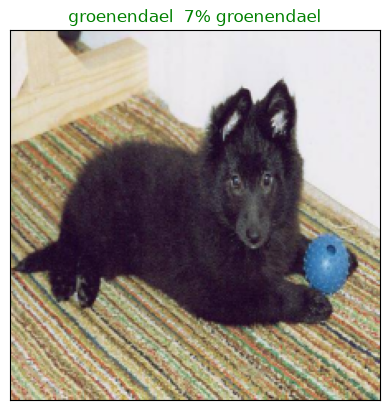

In [221]:
plot_pred(prediction_probabilities=predictions,
          labels=val_labels,
          images=val_images,
          n=77)


In [222]:
def plot_pred_conf(prediction_probabilities, labels, n=1):
  """
  Plots the top 10 highest prediction confidences along with the truth label for sample n.
  """
  pred_prob, true_label = prediction_probabilities[n], labels[n]

  # Get the predicted label
  pred_label = get_pred_label(pred_prob)

  # Find the top 10 prediction confidence indexes
  top_10_pred_indexes = pred_prob.argsort()[-10:][::-1]
  # Find the top 10 prediction confidence values
  top_10_pred_values = pred_prob[top_10_pred_indexes]
  # Find the top 10 prediction labels
  top_10_pred_labels = unique_breeds[top_10_pred_indexes]

  # Setup plot
  top_plot = plt.bar(np.arange(len(top_10_pred_labels)),
                     top_10_pred_values,
                     color="grey")
  plt.xticks(np.arange(len(top_10_pred_labels)),
             labels=top_10_pred_labels,
             rotation="vertical")

  # Change color of true label
  if np.isin(true_label, top_10_pred_labels):
    top_plot[np.argmax(top_10_pred_labels == true_label)].set_color("green")
  else:
    pass


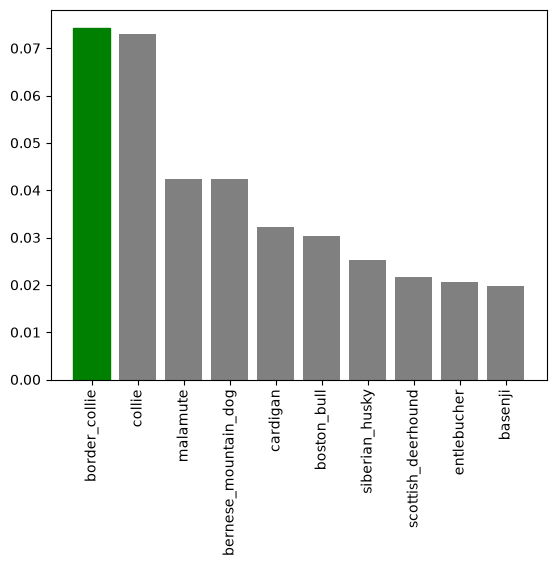

In [223]:
plot_pred_conf(prediction_probabilities=predictions,
               labels=val_labels,
               n=9)


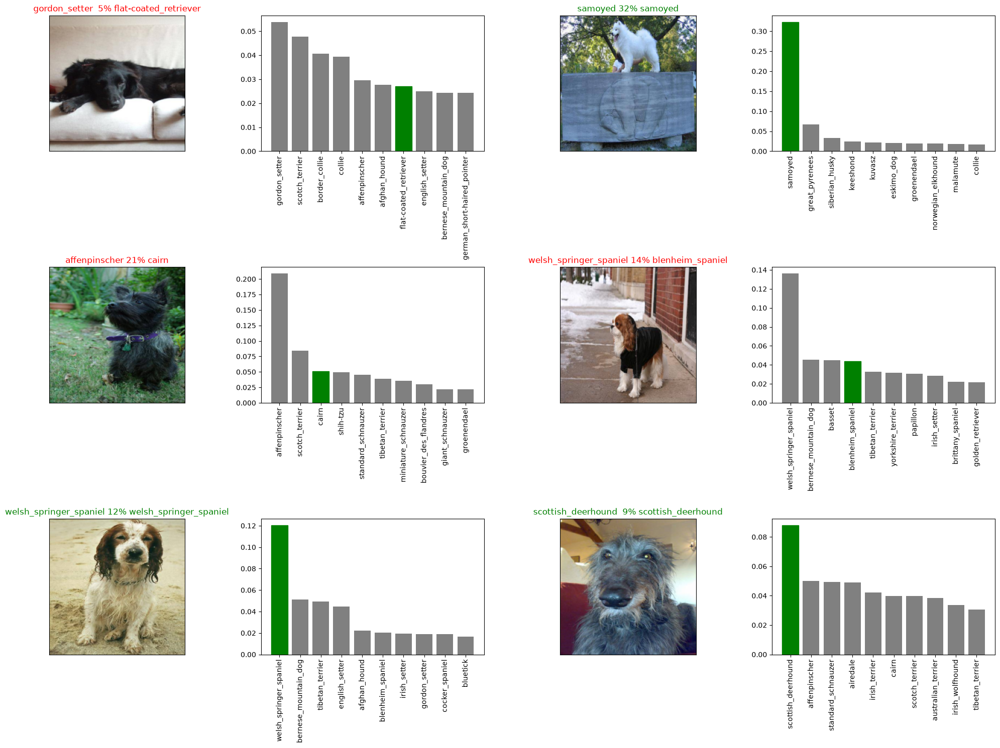

In [224]:
# Let's check out a few predictions and their different values
i_multiplier = 20
num_rows = 3
num_cols = 2
num_images = num_rows * num_cols
plt.figure(figsize=(10 * num_cols, 5 * num_rows))
for i in range(num_images):
  plt.subplot(num_rows, 2 * num_cols, 2 * i + 1)
  plot_pred(prediction_probabilities=predictions,
            labels=val_labels,
            images=val_images,
            n=i + i_multiplier)
  plt.subplot(num_rows, 2 * num_cols, 2 * i + 2)
  plot_pred_conf(prediction_probabilities=predictions,
                 labels=val_labels,
                 n=i + i_multiplier)
plt.tight_layout(h_pad=1.0)
plt.show()


## 4. Saving and reloading a trained model

In [225]:
# Create a function to save a model
def save_model(model, suffix=None):
    modeldir = os.path.join("", "models")
    os.makedirs(modeldir, exist_ok=True)

    timestamp = datetime.datetime.now().strftime("%Y%m%d-%H%M%S")
    model_path = os.path.join(
        modeldir,
        f"{timestamp}-{suffix}.pt"
    )

    print(f"Saving model to: {model_path}...")

    torch.save({
        "state_dict": model.state_dict(),
        "unique_breeds": [str(b) for b in unique_breeds]
    }, model_path)

    print("Model saved successfully!")


In [226]:
# Create a function to load a trained model
def load_model(model_path):
  """
  Loads a saved model from a specified path.
  """
  print(f"Loading saved model from: {model_path}")
  checkpoint = torch.load(model_path, map_location=device)
  loaded_model = create_model(output_shape=len(checkpoint["unique_breeds"]))
  loaded_model.load_state_dict(checkpoint["state_dict"])
  loaded_model.eval()
  return loaded_model


In [236]:
# Save our model trained on 1000 images
save_model(model, suffix="new-1000-images-mobilenetv2-Adam")

Saving model to: models\20260929-173336-new-1000-images-mobilenetv2-Adam.pt...
Model saved successfully!


In [239]:
# Load a trained model
loaded_1000_image_model = load_model("models/20260929-173336-new-1000-images-mobilenetv2-Adam.pt")

Loading saved model from: models/20260929-173336-new-1000-images-mobilenetv2-Adam.pt
Building model with a pretrained MobileNetV2 backbone


In [240]:
def evaluate_model(model, dataloader):
  """
  Evaluates a model on a DataLoader, returning (avg_loss, accuracy) -
  the PyTorch equivalent of model.evaluate().
  """
  criterion = nn.CrossEntropyLoss()
  return evaluate(model, dataloader, criterion, device)


In [241]:
# Evaluate the pre-saved model
evaluate_model(model, val_data)


(2.633690414428711, 0.48)

In [246]:
# Evaluate the loaded model
evaluate_model(loaded_1000_image_model, val_data)


(2.633690414428711, 0.48)

## 5. Training a model on the full dataset

In [247]:
len(X), len(y)


(10222, 10222)

In [248]:
# Create a data batch with the full data set
full_data = create_data_batches(X, y)


Creating training data batches...


In [249]:
full_data


In [251]:
# Train the full model on the full dataset. There's no validation set here,
# so early stopping watches training accuracy instead (equivalent to
# monitor="accuracy", patience=3 in the original notebook).

full_model = train_model(full_data, val_dataloader=None, epochs=NUM_EPOCHS, patience=5)


Building model with a pretrained MobileNetV2 backbone
Epoch 1/100 - train_loss: 4.1948 - train_acc: 0.1382
Epoch 2/100 - train_loss: 3.0818 - train_acc: 0.4417
Epoch 3/100 - train_loss: 2.4184 - train_acc: 0.5706
Epoch 4/100 - train_loss: 1.9987 - train_acc: 0.6342
Epoch 5/100 - train_loss: 1.7181 - train_acc: 0.6750
Epoch 6/100 - train_loss: 1.5320 - train_acc: 0.7051
Epoch 7/100 - train_loss: 1.3790 - train_acc: 0.7253
Epoch 8/100 - train_loss: 1.2741 - train_acc: 0.7354
Epoch 9/100 - train_loss: 1.1902 - train_acc: 0.7469
Epoch 10/100 - train_loss: 1.1201 - train_acc: 0.7529
Epoch 11/100 - train_loss: 1.0612 - train_acc: 0.7635
Epoch 12/100 - train_loss: 1.0144 - train_acc: 0.7716
Epoch 13/100 - train_loss: 0.9631 - train_acc: 0.7781
Epoch 14/100 - train_loss: 0.9271 - train_acc: 0.7825
Epoch 15/100 - train_loss: 0.8982 - train_acc: 0.7854
Epoch 16/100 - train_loss: 0.8701 - train_acc: 0.7913
Epoch 17/100 - train_loss: 0.8430 - train_acc: 0.7973
Epoch 18/100 - train_loss: 0.8118 - t

In [252]:
save_model(full_model, suffix="new-full-image-set-mobilenetv2-Adam")


Saving model to: models\20260929-181427-new-full-image-set-mobilenetv2-Adam.pt...
Model saved successfully!


In [253]:
# Load in the full model
loaded_full_model = load_model("models/20260929-181427-new-full-image-set-mobilenetv2-Adam.pt")


Loading saved model from: models/20260929-181427-new-full-image-set-mobilenetv2-Adam.pt
Building model with a pretrained MobileNetV2 backbone


## 6. Making predictions on the test dataset

In [254]:
# Load test image filenames
test_path = "test/"
test_filenames = [test_path + fname for fname in os.listdir(test_path)]
test_filenames[:10]


['test/000621fb3cbb32d8935728e48679680e.jpg',
 'test/00102ee9d8eb90812350685311fe5890.jpg',
 'test/0012a730dfa437f5f3613fb75efcd4ce.jpg',
 'test/001510bc8570bbeee98c8d80c8a95ec1.jpg',
 'test/001a5f3114548acdefa3d4da05474c2e.jpg',
 'test/00225dcd3e4d2410dd53239f95c0352f.jpg',
 'test/002c2a3117c2193b4d26400ce431eebd.jpg',
 'test/002c58d413a521ae8d1a5daeb35fc803.jpg',
 'test/002f80396f1e3db687c5932d7978b196.jpg',
 'test/0036c6bcec6031be9e62a257b1c3c442.jpg']

In [255]:
len(test_filenames)


10357

In [256]:

# Create test data batch
test_data = create_data_batches(test_filenames, test_data=True)


Creating test data batches...


In [257]:
test_data


In [259]:
# Make predictions on test data batch using the loaded full model
test_predictions = predict_probabilities(loaded_full_model, test_data)


In [260]:
# Save predictions (NumPy array) to csv file (for access later)
np.savetxt("new_preds_array.csv", test_predictions, delimiter=",")


In [261]:
# Load predictions (NumPy array) from csv file
test_predictions = np.loadtxt("new_preds_array.csv", delimiter=",")


In [262]:
test_predictions[:10]


array([[1.89219790e-07, 8.14264058e-05, 1.07730314e-09, ...,
        1.25586567e-07, 1.00608042e-06, 8.99876886e-06],
       [2.02608934e-08, 5.70854752e-10, 6.79412249e-10, ...,
        1.11163079e-09, 4.98841146e-09, 1.14243326e-09],
       [4.89976287e-07, 1.43564967e-02, 4.31166249e-08, ...,
        4.16269813e-06, 6.02774321e-07, 3.55992512e-07],
       ...,
       [2.60218115e-07, 7.02594321e-07, 2.54831303e-08, ...,
        1.87176752e-07, 5.80896585e-06, 8.62653178e-06],
       [1.64529760e-04, 2.69295095e-04, 9.71425288e-06, ...,
        1.17280164e-04, 1.04626961e-04, 4.41400334e-05],
       [1.88103115e-06, 6.26145379e-07, 4.06118694e-08, ...,
        4.69390526e-10, 4.54898355e-07, 3.52756757e-07]], shape=(10, 120))

In [263]:
test_predictions.shape


(10357, 120)

### Preparing our test dataset predictions for Kaggle

In [264]:
# Create a pandas DataFrame with empty columns
preds_df = pd.DataFrame(columns=["id"] + list(unique_breeds))
preds_df.head()


,id,affenpinscher,afghan_hound,african_hunting_dog,airedale,american_staffordshire_terrier,appenzeller,australian_terrier,basenji,basset,...,toy_poodle,toy_terrier,vizsla,walker_hound,weimaraner,welsh_springer_spaniel,west_highland_white_terrier,whippet,wire-haired_fox_terrier,yorkshire_terrier


In [265]:
# Append test image ID's to predictions DataFrame
test_ids = [os.path.splitext(os.path.basename(path))[0] for path in test_filenames]
preds_df["id"] = test_ids


In [266]:
preds_df.head()


,id,affenpinscher,afghan_hound,african_hunting_dog,airedale,american_staffordshire_terrier,appenzeller,australian_terrier,basenji,basset,...,toy_poodle,toy_terrier,vizsla,walker_hound,weimaraner,welsh_springer_spaniel,west_highland_white_terrier,whippet,wire-haired_fox_terrier,yorkshire_terrier
0,000621fb3cbb32d8935728e48679680e,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,00102ee9d8eb90812350685311fe5890,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,0012a730dfa437f5f3613fb75efcd4ce,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,001510bc8570bbeee98c8d80c8a95ec1,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,001a5f3114548acdefa3d4da05474c2e,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [267]:
# Add the prediction probabilities to each dog breed column
preds_df[list(unique_breeds)] = test_predictions
preds_df.head()


,id,affenpinscher,afghan_hound,african_hunting_dog,airedale,american_staffordshire_terrier,appenzeller,australian_terrier,basenji,basset,...,toy_poodle,toy_terrier,vizsla,walker_hound,weimaraner,welsh_springer_spaniel,west_highland_white_terrier,whippet,wire-haired_fox_terrier,yorkshire_terrier
0,000621fb3cbb32d8935728e48679680e,1.892198e-07,8.142641e-05,1.077303e-09,1.564701e-09,6.256771e-08,3.260425e-06,1.594244e-06,1.064883e-06,9.551165e-07,...,1.953922e-07,9.414161e-07,1.679305e-07,4.218344e-07,2.706295e-09,3.766234e-05,5.190045e-08,1.255866e-07,1.006080e-06,8.998769e-06
1,00102ee9d8eb90812350685311fe5890,2.026089e-08,5.708548e-10,6.794122e-10,3.703339e-10,3.164823e-08,2.164363e-07,1.142882e-07,5.294844e-09,8.389105e-11,...,2.416420e-08,4.213760e-09,4.375902e-10,3.266567e-09,1.480154e-09,7.419708e-09,1.131942e-05,1.111631e-09,4.988411e-09,1.142433e-09
2,0012a730dfa437f5f3613fb75efcd4ce,4.899763e-07,1.435650e-02,4.311662e-08,2.017843e-08,8.422010e-08,4.832535e-07,1.104915e-06,2.822009e-09,6.617599e-07,...,4.693361e-08,9.117158e-08,9.908183e-07,5.487237e-06,4.487584e-05,2.333085e-03,7.815968e-07,4.162698e-06,6.027743e-07,3.559925e-07
3,001510bc8570bbeee98c8d80c8a95ec1,1.103837e-01,6.946040e-03,2.417482e-05,1.212578e-03,1.560370e-03,5.964277e-03,5.439669e-05,5.755510e-03,3.417330e-04,...,2.208401e-02,1.266207e-04,1.053676e-02,1.441067e-03,1.553559e-03,1.470162e-04,6.489980e-06,3.914411e-02,6.152013e-05,2.250962e-03
4,001a5f3114548acdefa3d4da05474c2e,5.678117e-03,1.294058e-04,1.154906e-08,1.232025e-07,9.805659e-07,7.320848e-07,1.792265e-04,2.390876e-07,1.176409e-07,...,3.525939e-05,7.762265e-07,6.424345e-09,4.327398e-07,1.260407e-08,6.844442e-07,7.498347e-05,2.144632e-07,2.946159e-04,5.748551e-05


In [268]:
# Save our predictions dataframe to CSV 
preds_df.to_csv("full_model_predictions_submission_1_mobilenetV2.csv",
                index=False)


## 7. Making predictions on custom images

In [286]:
# Get custom image filepaths
custom_path = "my_imgs/"
custom_image_paths = [custom_path + fname for fname in os.listdir(custom_path)]


In [287]:
custom_image_paths


['my_imgs/american-pitbull-1.jpg',
 'my_imgs/c27a68548d044f11ec1c4922ccbf5f6b.jpg',
 'my_imgs/download.webp',
 'my_imgs/g.jpg',
 'my_imgs/images (1).jpg',
 'my_imgs/images (10).jpg',
 'my_imgs/images (2).jpg',
 'my_imgs/images (3).jpg',
 'my_imgs/images (4).jpg',
 'my_imgs/images (5).jpg',
 'my_imgs/images (6).jpg',
 'my_imgs/images (7).jpg',
 'my_imgs/images (8).jpg',
 'my_imgs/images (9).jpg',
 'my_imgs/images.jpg',
 'my_imgs/Labrador_Retriever_portrait.jpg',
 'my_imgs/Pastoral Dog Breeds.avif',
 'my_imgs/steptodown_3.webp']

In [288]:
# Turn custom images into a batch dataset
custom_data = create_data_batches(custom_image_paths, test_data=True)
custom_data


Creating test data batches...


In [289]:
# Make predictions on the custom data
custom_preds = predict_probabilities(loaded_full_model, custom_data)


In [290]:
custom_preds.shape


(18, 120)

In [291]:
# Get custom image prediction labels
custom_pred_labels = [get_pred_label(custom_preds[i]) for i in range(len(custom_preds))]
custom_pred_labels


['american_staffordshire_terrier',
 'american_staffordshire_terrier',
 'doberman',
 'dhole',
 'bull_mastiff',
 'great_dane',
 'bull_mastiff',
 'golden_retriever',
 'dhole',
 'dhole',
 'great_dane',
 'scotch_terrier',
 'scotch_terrier',
 'great_dane',
 'bull_mastiff',
 'labrador_retriever',
 'german_shepherd',
 'pug']

In [292]:
# Get the custom images themselves (unnormalized, ready for display)
custom_images = []
for batch in custom_data:
  images = batch[0] if isinstance(batch, (list, tuple)) else batch
  for image in images:
    custom_images.append(unnormalize(image))


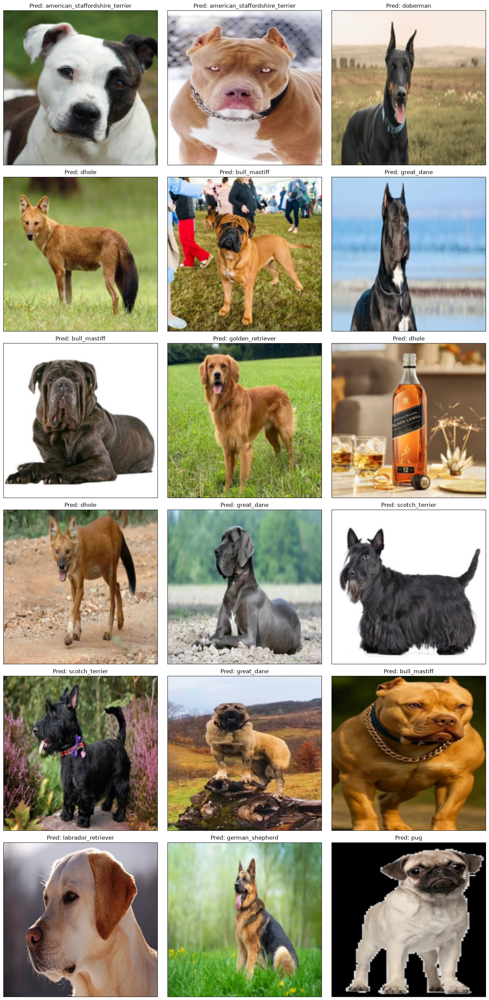

In [293]:
import math
n = len(custom_images)
cols = 3
rows = math.ceil(n / cols)

plt.figure(figsize=(15, 5 * rows))

for i, image in enumerate(custom_images):
    plt.subplot(rows, cols, i + 1)
    plt.xticks([])
    plt.yticks([])

    plt.title(f"Pred: {custom_pred_labels[i]}")

    plt.imshow(image)

plt.tight_layout()
plt.show()